In [1]:
import pandas as pd

In [2]:
db = pd.read_csv("/home/cristoshie/cancelation/data/cancelamentos.csv")

In [3]:
db.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              50000 non-null  float64
 1   idade                   50000 non-null  float64
 2   sexo                    49997 non-null  str    
 3   tempo_como_cliente      49998 non-null  float64
 4   frequencia_uso          50000 non-null  float64
 5   ligacoes_callcenter     50000 non-null  float64
 6   dias_atraso             50000 non-null  float64
 7   assinatura              50000 non-null  str    
 8   duracao_contrato        50000 non-null  str    
 9   total_gasto             50000 non-null  float64
 10  meses_ultima_interacao  50000 non-null  float64
 11  cancelou                50000 non-null  float64
dtypes: float64(9), str(3)
memory usage: 4.6 MB


In [4]:
db.head(10)

,CustomerID,idade,sexo,tempo_como_cliente,frequencia_uso,ligacoes_callcenter,dias_atraso,assinatura,duracao_contrato,total_gasto,meses_ultima_interacao,cancelou
0,349936.0,23.0,Male,13.0,22.0,2.0,1.0,Standard,Annual,909.58,23.0,0.0
1,100634.0,49.0,Male,55.0,16.0,3.0,6.0,Premium,Monthly,207.00,29.0,1.0
2,301263.0,30.0,Male,7.0,1.0,0.0,8.0,Basic,Annual,768.78,7.0,0.0
3,119358.0,26.0,Male,40.0,5.0,3.0,8.0,Premium,Annual,398.00,12.0,1.0
4,130955.0,27.0,Female,17.0,30.0,5.0,6.0,Basic,Annual,507.00,15.0,1.0
5,423992.0,30.0,NaN,NaN,12.0,3.0,7.0,Standard,Quarterly,641.78,7.0,0.0
6,345190.0,49.0,Male,6.0,7.0,0.0,0.0,Standard,Annual,751.00,11.0,0.0
7,405747.0,33.0,Male,15.0,18.0,1.0,20.0,Standard,Annual,839.71,25.0,0.0
8,298708.0,19.0,Female,59.0,19.0,1.0,4.0,Basic,Quarterly,543.93,7.0,0.0
9,269544.0,27.0,Female,1.0,13.0,0.0,11.0,Premium,Annual,621.67,6.0,0.0


In [5]:
db = db.drop(columns = "CustomerID")
db.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   idade                   50000 non-null  float64
 1   sexo                    49997 non-null  str    
 2   tempo_como_cliente      49998 non-null  float64
 3   frequencia_uso          50000 non-null  float64
 4   ligacoes_callcenter     50000 non-null  float64
 5   dias_atraso             50000 non-null  float64
 6   assinatura              50000 non-null  str    
 7   duracao_contrato        50000 non-null  str    
 8   total_gasto             50000 non-null  float64
 9   meses_ultima_interacao  50000 non-null  float64
 10  cancelou                50000 non-null  float64
dtypes: float64(8), str(3)
memory usage: 4.2 MB


In [6]:
db = db.drop_duplicates()
db.info()

<class 'pandas.DataFrame'>
Index: 48531 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   idade                   48531 non-null  float64
 1   sexo                    48528 non-null  str    
 2   tempo_como_cliente      48529 non-null  float64
 3   frequencia_uso          48531 non-null  float64
 4   ligacoes_callcenter     48531 non-null  float64
 5   dias_atraso             48531 non-null  float64
 6   assinatura              48531 non-null  str    
 7   duracao_contrato        48531 non-null  str    
 8   total_gasto             48531 non-null  float64
 9   meses_ultima_interacao  48531 non-null  float64
 10  cancelou                48531 non-null  float64
dtypes: float64(8), str(3)
memory usage: 4.4 MB


In [7]:
db = db.dropna()
db.info()

<class 'pandas.DataFrame'>
Index: 48527 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   idade                   48527 non-null  float64
 1   sexo                    48527 non-null  str    
 2   tempo_como_cliente      48527 non-null  float64
 3   frequencia_uso          48527 non-null  float64
 4   ligacoes_callcenter     48527 non-null  float64
 5   dias_atraso             48527 non-null  float64
 6   assinatura              48527 non-null  str    
 7   duracao_contrato        48527 non-null  str    
 8   total_gasto             48527 non-null  float64
 9   meses_ultima_interacao  48527 non-null  float64
 10  cancelou                48527 non-null  float64
dtypes: float64(8), str(3)
memory usage: 4.4 MB


In [8]:
# quantidade de clientes que cancelaram
db["cancelou"].value_counts()

cancelou
1.0    27539
0.0    20988
Name: count, dtype: int64

In [9]:
# pocentagem de cancelamentos
db["cancelou"].value_counts(normalize=True)

cancelou
1.0    0.567499
0.0    0.432501
Name: proportion, dtype: float64

In [10]:
import plotly.express as px

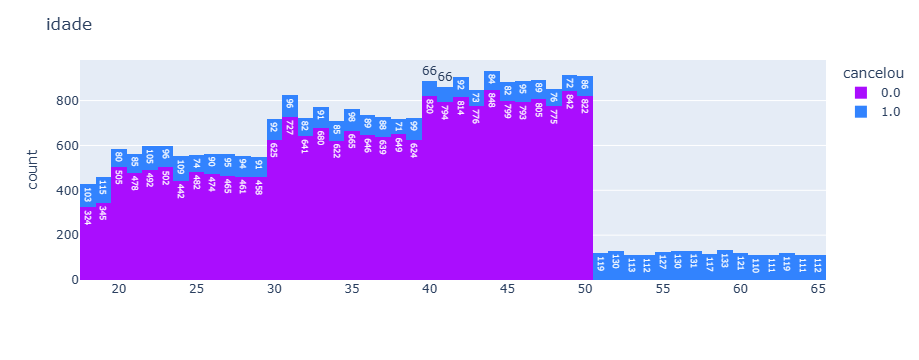

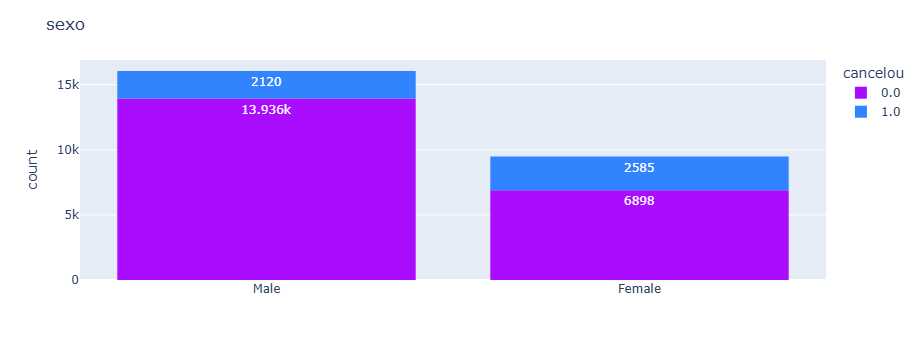

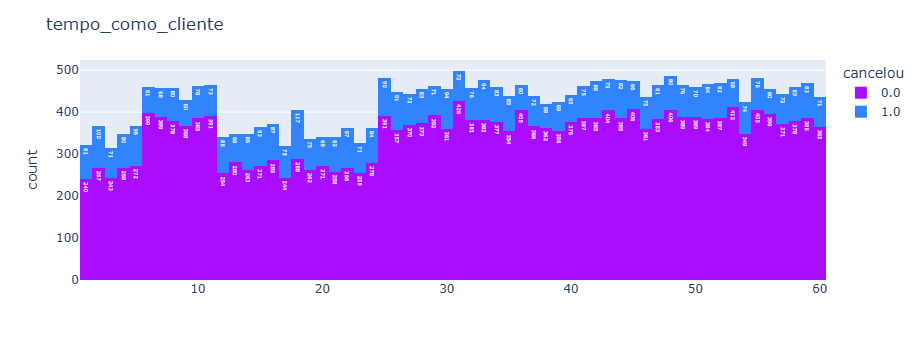

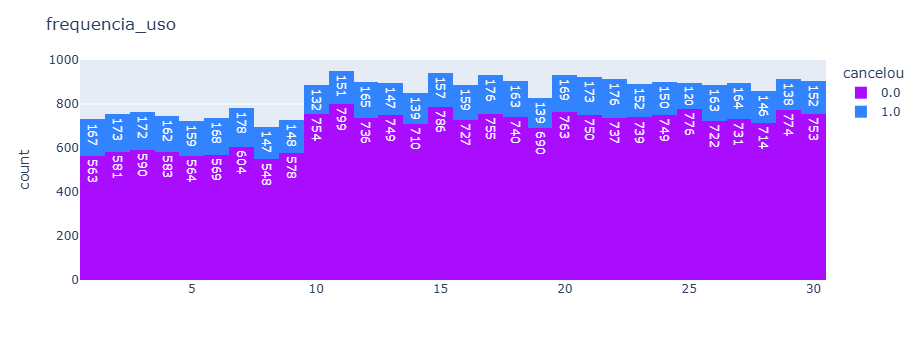

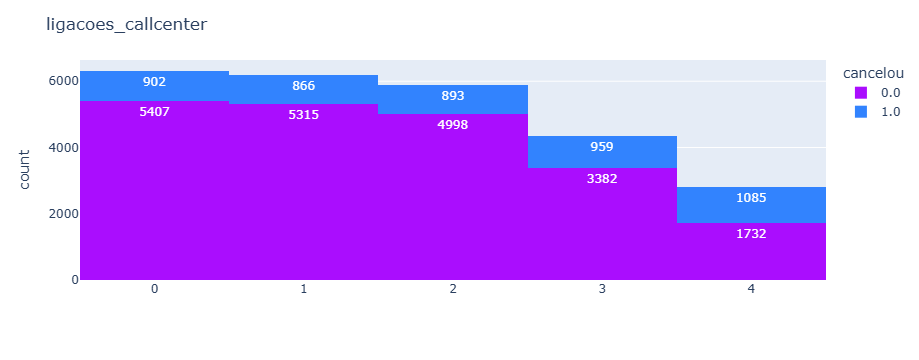

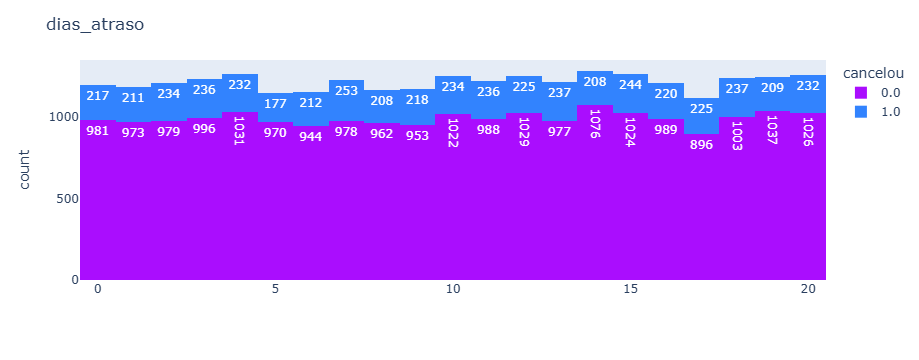

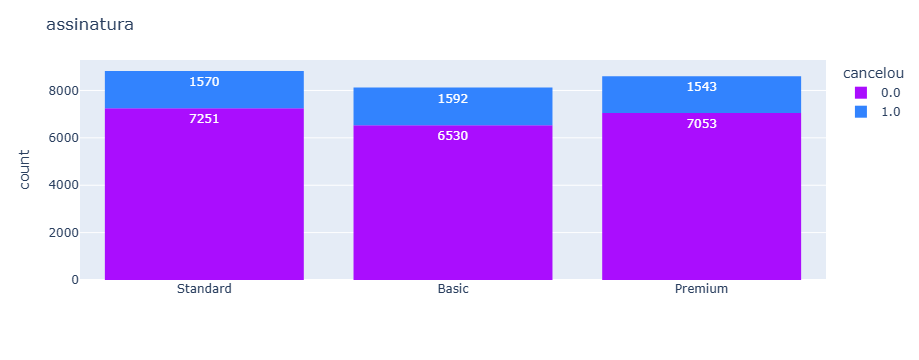

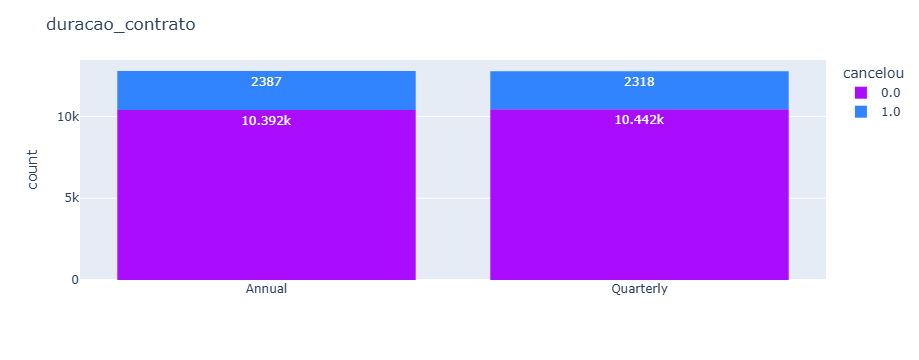

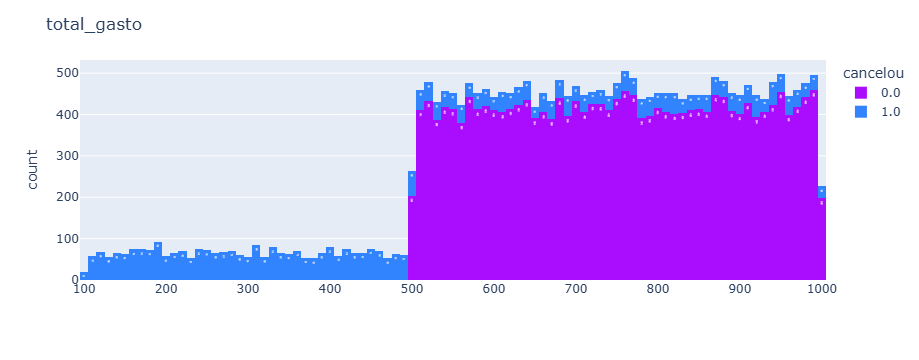

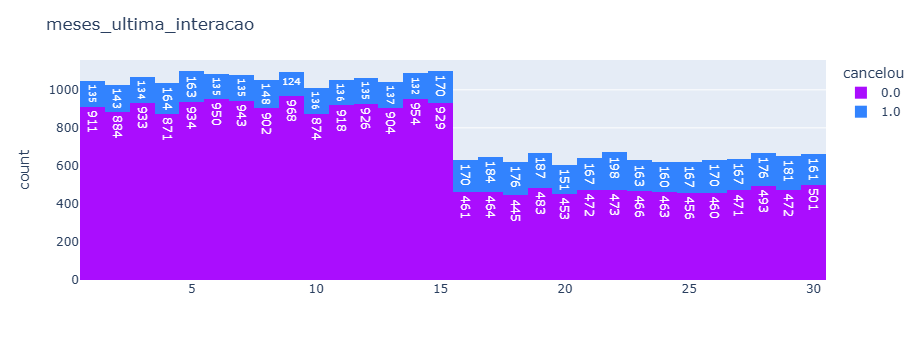

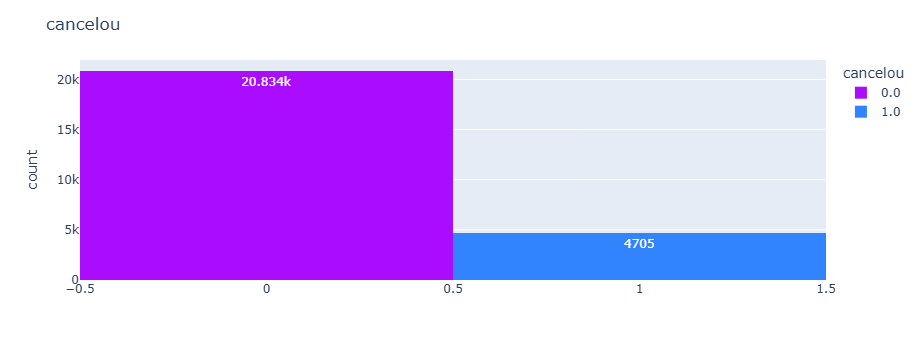

In [13]:
# análise detalhada dos dados de cancelamento

for column in db.columns:
    graph = px.histogram(
        db, 
        x = column, 
        color = "cancelou",
        text_auto = True,
        color_discrete_sequence = px.colors.qualitative.Alphabet)
    graph.update_layout(
        title_text = column,
        xaxis_title_text = "",
        yaxis_title_text = "count")
    graph.show()

Problemas:
1. Ligações de call center: clientes que ligaram mais de 4x no call center, cancelaram o contrato;
2. Duração do contrato: clientes com contratos mensais tem tendência maior de cancelar;
3. Clientes que atrasaram mais de 20 dias cancelam;

In [12]:
#porcentagem inicial de cancelamentos = 56%

# duracao_contrato != mensal
db = db[db["duracao_contrato"] != "Monthly"]
# ligacoes_callcenter <= 4
db = db[db["ligacoes_callcenter"] <= 4]
# dias_atraso <= 20
db = db[db["dias_atraso"] <= 20]

# procentagem final 
db["cancelou"].value_counts(normalize = True)

cancelou
0.0    0.815772
1.0    0.184228
Name: proportion, dtype: float64

Resultado:
Após resolver os problemas diagnosticados pela análise de dados, o cancelamento de clientes caiu de 56,8% para 18,4%.